# 06. ĐỐI SÁNH MÔ HÌNH, DỊCH CHUYỂN NGƯỠNG & TỐI ƯU HÓA MA TRẬN CHI PHÍ
## (Model Comparison, Threshold Tuning & Cost Matrix Optimization)

* **Học phần:** Khai phá Dữ liệu (Data Mining) — Học viện Công nghệ Bưu chính Viễn thông (PTIT)
* **Đề tài 13:** Credit Card Fraud Detection (Unsupervised Anomaly Detection)
* **Nhóm thực hiện:**
  * **Nguyễn Văn Hiển Vinh (B23DCVT461)** — Leader / Data Preprocessing & Validation
  * **Nguyễn Minh Hoàng (B23DCVT173)** — Modeling & Evaluation Lead
* **Mục tiêu học thuật của Phase 6:**
  1. Nạp và đánh giá độc lập 3 mô hình học không giám sát đã được huấn luyện và tối ưu từ Phase 3, 4, 5:
     * **Isolation Forest (Phase 3)** — Phân tách cây ngẫu nhiên đa chiều
     * **Local Outlier Factor (Phase 4)** — Đo lường mật độ cục bộ qua $k$-láng giềng
     * **One-Class SVM (Phase 5)** — Bao bọc biên phi tuyến bằng RBF kernel
  2. So sánh toàn diện năng lực phân biệt thông qua đường cong **Precision-Recall Curve (PRC)** và chỉ số **Average Precision (AP / PR-AUC)** tính theo phương pháp Davis & Goadrich (ICML 2006).
  3. Xác định ngưỡng tối ưu F1-Score ($\tau_{\text{F1}}^*$) trên toàn bộ dải giá trị điểm thực tế.
  4. Xây dựng bài toán **Ma trận chi phí (Business Cost Matrix)** học thuật:
     * Giả định tỷ lệ chi phí tương đối: $C_{\text{FP}} = 1.0$, $C_{\text{FN}} = 30.0$ (kịch bản trọng tâm $30:1$).
     * Khảo sát độ nhạy qua 5 kịch bản: $C_{\text{FN}} / C_{\text{FP}} \in [10, 20, 30, 50, 100]$.
     * Sử dụng bộ giải chính xác tuyệt đối $O(N \log N)$ `find_optimal_cost_threshold_exact` để tìm $\tau_{\text{cost}}^*$.
  5. Thiết lập chính sách lựa chọn mô hình **Champion** minh bạch, đa tiêu chí và đóng băng (freeze) toàn bộ thông số trước khi thực hiện đánh giá cuối cùng ở Phase 8.
* **Nguyên tắc khoa học nghiêm ngặt:**
  * **Niêm phong tập Test tuyệt đối:** Toàn bộ quá trình so sánh và tối ưu ngưỡng CHỈ ĐƯỢC PHÉP diễn ra trên tập Validation ($N_{\text{val}} = 42,721$). Tập Test ($42,722$ mẫu) được niêm phong 100% để bảo đảm tính khách quan, chống Data Snooping.
  * **Quy ước điểm số dị biệt (Anomaly Score Convention):** Điểm số càng cao phản ánh mức độ bất thường càng lớn. Anomaly score không phải là xác suất gian lận.
  * **Tính tái lập (Reproducibility):** Cố định hạt giống ngẫu nhiên `RANDOM_STATE = 42`.


In [1]:
# ==============================================================================
# CELL 1: KHỞI TẠO MÔI TRƯỜNG, MODULES & CẤU HÌNH ĐỒ THỊ CHUẨN XUẤT BẢN
# ==============================================================================
import sys
import json
import time
from pathlib import Path

# Thêm thư mục gốc dự án vào PYTHONPATH để nạp các module nội bộ src/
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Nạp cấu hình và các hàm chuyên biệt từ src/
from src.config import (
    RANDOM_STATE,
    COST_FP,
    DEFAULT_COST_FN,
    COST_RATIOS,
    FIGURES_DIR
)
from src.models import compute_unified_anomaly_scores
from src.metrics import (
    evaluate_threshold,
    compute_auprc,
    find_optimal_cost_threshold_exact
)

# Thiết lập phong cách đồ thị Seaborn & Matplotlib chuẩn IEEE/Academic
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

MODEL_COLORS = {
    "Isolation Forest": "#1f77b4",     # Xanh dương đậm
    "Local Outlier Factor": "#2ca02c", # Xanh lá cây đậm
    "One-Class SVM": "#d62728"         # Đỏ đậm
}

MODEL_LINESTYLES = {
    "Isolation Forest": "--",
    "Local Outlier Factor": "-",
    "One-Class SVM": "-."
}

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"[THÀNH CÔNG] Đã nạp môi trường làm việc từ: {PROJECT_ROOT}")
print(f"  - Random State: {RANDOM_STATE}")
print(f"  - Cost Matrix chuẩn: C_FP = {COST_FP}, C_FN = {DEFAULT_COST_FN} (Tỷ lệ chính {DEFAULT_COST_FN/COST_FP:.0f}:1)")
print(f"  - Dải tỷ lệ khảo sát độ nhạy: {COST_RATIOS}")
print(f"  - Thư mục lưu trữ biểu đồ: {FIGURES_DIR}")


[THÀNH CÔNG] Đã nạp môi trường làm việc từ: C:\Users\Vinh Nguyen\DATAMINING
  - Random State: 42
  - Cost Matrix chuẩn: C_FP = 1.0, C_FN = 30.0 (Tỷ lệ chính 30:1)
  - Dải tỷ lệ khảo sát độ nhạy: [10.0, 20.0, 30.0, 50.0, 100.0]
  - Thư mục lưu trữ biểu đồ: C:\Users\Vinh Nguyen\DATAMINING\reports\figures


---
## PHẦN B: NẠP DỮ LIỆU VALIDATION & CHECKPOINT 3 MÔ HÌNH ĐÃ HUẤN LUYỆN

> **Nguyên tắc bảo vệ Test Set (Zero Information Leakage):**  
> Trong học máy ứng dụng phát hiện gian lận tài chính, việc dò tìm tham số hoặc lựa chọn mô hình trên tập Test sẽ dẫn đến sai lệch lạc quan thái quá (Data Snooping Bias).  
> Chúng ta **chỉ nạp duy nhất tập Validation** ($X_{\text{val}}, y_{\text{val}}$) để so sánh và đóng băng mọi ngưỡng quyết định.


In [2]:
# ==============================================================================
# CELL 4: NẠP DỮ LIỆU VALIDATION TỪ PREPROCESSED ARTIFACT
# ==============================================================================
processed_data_path = PROJECT_ROOT / "data" / "processed" / "creditcard_preprocessed.npz"
if not processed_data_path.exists():
    raise FileNotFoundError(f"Không tìm thấy file tiền xử lý: {processed_data_path}")

npz_data = np.load(processed_data_path, allow_pickle=True)

# Chỉ nạp duy nhất X_val, y_val; tuyệt đối không nạp X_test, y_test
X_val = npz_data["X_val"]
y_val = npz_data["y_val"]

n_val_samples = len(y_val)
n_val_fraud = int(np.sum(y_val))
n_val_normal = n_val_samples - n_val_fraud
val_fraud_ratio = (n_val_fraud / n_val_samples) * 100

print(f"[DỮ LIỆU VALIDATION] File nguồn: {processed_data_path.name}")
print(f"  - Kích thước tập Validation: {X_val.shape[0]:,} dòng x {X_val.shape[1]} đặc trưng")
print(f"  - Giao dịch bình thường (Normal): {n_val_normal:,} ({100 - val_fraud_ratio:.4f}%)")
print(f"  - Giao dịch gian lận (Fraud): {n_val_fraud:,} ({val_fraud_ratio:.4f}%)")
print(f"  - Baseline tỷ lệ gian lận (No-Skill): P / N = {val_fraud_ratio/100:.6f}")

assert n_val_samples == 42721, f"Kỳ vọng 42,721 mẫu Validation nhưng nhận {n_val_samples}"
assert n_val_fraud == 74, f"Kỳ vọng đúng 74 mẫu Fraud trong Validation nhưng nhận {n_val_fraud}"
print("  => Kiểm tra số lượng và phân bố lớp: CHÍNH XÁC 100%!")


[DỮ LIỆU VALIDATION] File nguồn: creditcard_preprocessed.npz
  - Kích thước tập Validation: 42,721 dòng x 30 đặc trưng
  - Giao dịch bình thường (Normal): 42,647 (99.8268%)
  - Giao dịch gian lận (Fraud): 74 (0.1732%)
  - Baseline tỷ lệ gian lận (No-Skill): P / N = 0.001732
  => Kiểm tra số lượng và phân bố lớp: CHÍNH XÁC 100%!


In [3]:
# ==============================================================================
# CELL 5: NẠP CHECKPOINT CỦA 3 MÔ HÌNH TỪ THƯ MỤC MODELS/
# ==============================================================================
models_dir = PROJECT_ROOT / "models"

# Kiểm tra đường dẫn chính xác từng checkpoint
model_checkpoints = {
    "Isolation Forest": models_dir / "isolation_forest_best.joblib",
    "Local Outlier Factor": models_dir / "lof_best.joblib",
    "One-Class SVM": models_dir / "ocsvm_best.joblib"
}

loaded_models = {}
model_file_sizes_mb = {}

print("KIỂM TRA VÀ NẠP CHECKPOINT MÔ HÌNH ĐÃ HUẤN LUYỆN:")
print("-" * 80)
for name, path in model_checkpoints.items():
    if not path.exists():
        raise FileNotFoundError(f"Thiếu file checkpoint: {path}")
    
    file_size_mb = path.stat().st_size / (1024 * 1024)
    model_file_sizes_mb[name] = file_size_mb
    
    t0 = time.perf_counter()
    model_obj = joblib.load(path)
    t_load = time.perf_counter() - t0
    
    loaded_models[name] = model_obj
    print(f"  [PASS] {name:<22}: {path.name:<28} | Size: {file_size_mb:6.2f} MB | Load time: {t_load*1000:6.2f} ms")

print("-" * 80)
print("  => Toàn bộ 3 mô hình đã được nạp thành công từ đĩa!")


KIỂM TRA VÀ NẠP CHECKPOINT MÔ HÌNH ĐÃ HUẤN LUYỆN:
--------------------------------------------------------------------------------
  [PASS] Isolation Forest      : isolation_forest_best.joblib | Size:   2.41 MB | Load time:  76.55 ms
  [PASS] Local Outlier Factor  : lof_best.joblib              | Size:  11.83 MB | Load time:  11.23 ms
  [PASS] One-Class SVM         : ocsvm_best.joblib            | Size:   0.06 MB | Load time:   0.81 ms
--------------------------------------------------------------------------------
  => Toàn bộ 3 mô hình đã được nạp thành công từ đĩa!


In [4]:
# ==============================================================================
# CELL 6: TÍNH TOÁN ANOMALY SCORES VÀ ĐO LƯỜNG ĐỘ TRỄ SUY LUẬN (INFERENCE LATENCY)
# ==============================================================================
# Lưu ý khoa học: Độ trễ suy luận đo lường trong notebook là benchmark phần cứng cục bộ,
# phản ánh chi phí tính toán tương đối giữa các thuật toán, không khẳng định là SLA ngân hàng thực tế.
model_tags = {
    "Isolation Forest": "iForest",
    "Local Outlier Factor": "LOF",
    "One-Class SVM": "OCSVM"
}

anomaly_scores = {}
inference_times_sec = {}
latency_per_sample_ms = {}

print("TÍNH TOÁN ANOMALY SCORES & BENCHMARK SUY LUẬN TRÊN TẬP VALIDATION (42,721 MẪU):")
print("-" * 90)
print(f"{'Mô hình':<22} | {'Tổng thời gian (s)':<18} | {'Độ trễ (ms/tx)':<16} | {'Min Score':<12} | {'Max Score':<12}")
print("-" * 90)

for name, model in loaded_models.items():
    tag = model_tags[name]
    
    # Đo thời gian suy luận
    t_start = time.perf_counter()
    scores = compute_unified_anomaly_scores(model, X_val, model_name=tag)
    t_total = time.perf_counter() - t_start
    
    # Kiểm tra tính hợp lệ của mảng điểm
    assert len(scores) == n_val_samples, f"Kích thước scores {len(scores)} không khớp X_val"
    assert not np.isnan(scores).any(), f"Điểm số của {name} chứa NaN"
    assert not np.isinf(scores).any(), f"Điểm số của {name} chứa Inf"
    
    anomaly_scores[name] = scores
    inference_times_sec[name] = t_total
    latency_per_sample_ms[name] = (t_total / n_val_samples) * 1000
    
    print(
        f"{name:<22} | {t_total:18.4f} | {latency_per_sample_ms[name]:16.4f} | "
        f"{np.min(scores):12.4f} | {np.max(scores):12.4f}"
    )

print("-" * 90)
print("  => Quy ước đồng nhất: Điểm số càng cao phản ánh mức độ bất thường càng lớn.")


TÍNH TOÁN ANOMALY SCORES & BENCHMARK SUY LUẬN TRÊN TẬP VALIDATION (42,721 MẪU):
------------------------------------------------------------------------------------------
Mô hình                | Tổng thời gian (s) | Độ trễ (ms/tx)   | Min Score    | Max Score   
------------------------------------------------------------------------------------------


Isolation Forest       |             0.5832 |           0.0137 |       0.3437 |       0.7784


Local Outlier Factor   |             3.0967 |           0.0725 |       0.9444 |       9.1253


One-Class SVM          |             1.2839 |           0.0301 |      -4.2771 |       5.7610
------------------------------------------------------------------------------------------
  => Quy ước đồng nhất: Điểm số càng cao phản ánh mức độ bất thường càng lớn.


---
## PHẦN C: ĐÁNH GIÁ ĐỘC LẬP NGƯỠNG & PRECISION-RECALL CURVE

> **Tại sao sử dụng Average Precision (AP) thay vì ROC-AUC?**  
> Trong bài toán dữ liệu mất cân bằng cực đoan (tỷ lệ gian lận chỉ $0.1732\%$), chỉ số ROC-AUC sử dụng tỷ lệ False Positive Rate:
> $$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$
> Vì số lượng giao dịch bình thường (TN) quá áp đảo ($42,647$ mẫu), một lượng lớn cảnh báo sai (ví dụ $\text{FP} = 200$) chỉ tạo ra $\text{FPR} \approx 0.0047$, khiến ROC-AUC luôn duy trì mức rất cao ($> 0.90$) và tạo ảo giác hiệu năng giả tạo.  
> Ngược lại, **Precision-Recall Curve (PRC)** thay thế TN bằng Precision:
> $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
> Chỉ số **Average Precision (AP)** tính tổng có trọng số diện tích dưới đường cong theo từng bước nhảy của Recall (Davis & Goadrich, ICML 2006):
> $$\text{AP} = \sum_{k} (R_k - R_{k-1}) P_k$$
> Phản ánh trung thực năng lực bắt kẻ gian mà không bị phóng đại bởi số đông người tốt.


In [5]:
# ==============================================================================
# CELL 7: TÍNH TOÁN AP, ROC-AUC, NGƯỠNG F1-MAX & XÁC THỰC CHECKPOINT
# ==============================================================================
val_ap_scores = {}
val_roc_auc_scores = {}
pr_curve_data = {}

expected_ap_checkpoints = {
    "Isolation Forest": 0.103518,
    "Local Outlier Factor": 0.564948,
    "One-Class SVM": 0.251505
}

print("KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP NGƯỠNG TRÊN VALIDATION SET:")
print("-" * 90)
print(f"{'Mô hình':<22} | {'Val AP (PR-AUC)':<16} | {'ROC-AUC':<12} | {'AP Checkpoint':<14} | {'Sai số tuyệt đối'}")
print("-" * 90)

for name in loaded_models:
    scores = anomaly_scores[name]

    # 1. Tính AP chuẩn Davis & Goadrich và tọa độ PR-Curve qua helper dùng chung src/metrics.py
    ap, precisions, recalls, thresholds = compute_auprc(y_val, scores)
    val_ap_scores[name] = float(ap)

    # 2. Tính ROC-AUC tham khảo
    val_roc_auc_scores[name] = float(roc_auc_score(y_val, scores))

    # 3. Xác định điểm cực đại F1 một lần duy nhất để tái sử dụng cho đồ thị & bảng đối sánh
    denom = precisions[:-1] + recalls[:-1]
    f1_curve = np.divide(
        2 * precisions[:-1] * recalls[:-1],
        denom,
        out=np.zeros_like(precisions[:-1]),
        where=denom > 0
    )
    best_idx = int(np.argmax(f1_curve))

    pr_curve_data[name] = {
        "precisions": precisions,
        "recalls": recalls,
        "thresholds": thresholds,
        "tau_f1_star": float(thresholds[best_idx]),
        "p_opt": float(precisions[best_idx]),
        "r_opt": float(recalls[best_idx]),
        "f1_opt": float(f1_curve[best_idx])
    }

    # Kiểm tra đối chiếu với metadata checkpoint
    exp_ap = expected_ap_checkpoints[name]
    diff = abs(ap - exp_ap)
    print(f"{name:<22} | {ap:16.6f} | {val_roc_auc_scores[name]:12.4f} | {exp_ap:14.6f} | {diff:.2e}")
    assert diff < 1e-5, f"Lệch AP nghiêm trọng tại {name}: tính được {ap}, checkpoint {exp_ap}"

print("-" * 90)
print("  => XÁC THỰC HOÀN HẢO: Cả 3 mô hình khớp chính xác 100% với checkpoint độc lập Phase 3, 4, 5!")


KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP NGƯỠNG TRÊN VALIDATION SET:
------------------------------------------------------------------------------------------
Mô hình                | Val AP (PR-AUC)  | ROC-AUC      | AP Checkpoint  | Sai số tuyệt đối
------------------------------------------------------------------------------------------
Isolation Forest       |         0.103518 |       0.9434 |       0.103518 | 4.57e-08
Local Outlier Factor   |         0.564948 |       0.9402 |       0.564948 | 5.76e-08
One-Class SVM          |         0.251505 |       0.9006 |       0.251505 | 4.20e-07
------------------------------------------------------------------------------------------
  => XÁC THỰC HOÀN HẢO: Cả 3 mô hình khớp chính xác 100% với checkpoint độc lập Phase 3, 4, 5!


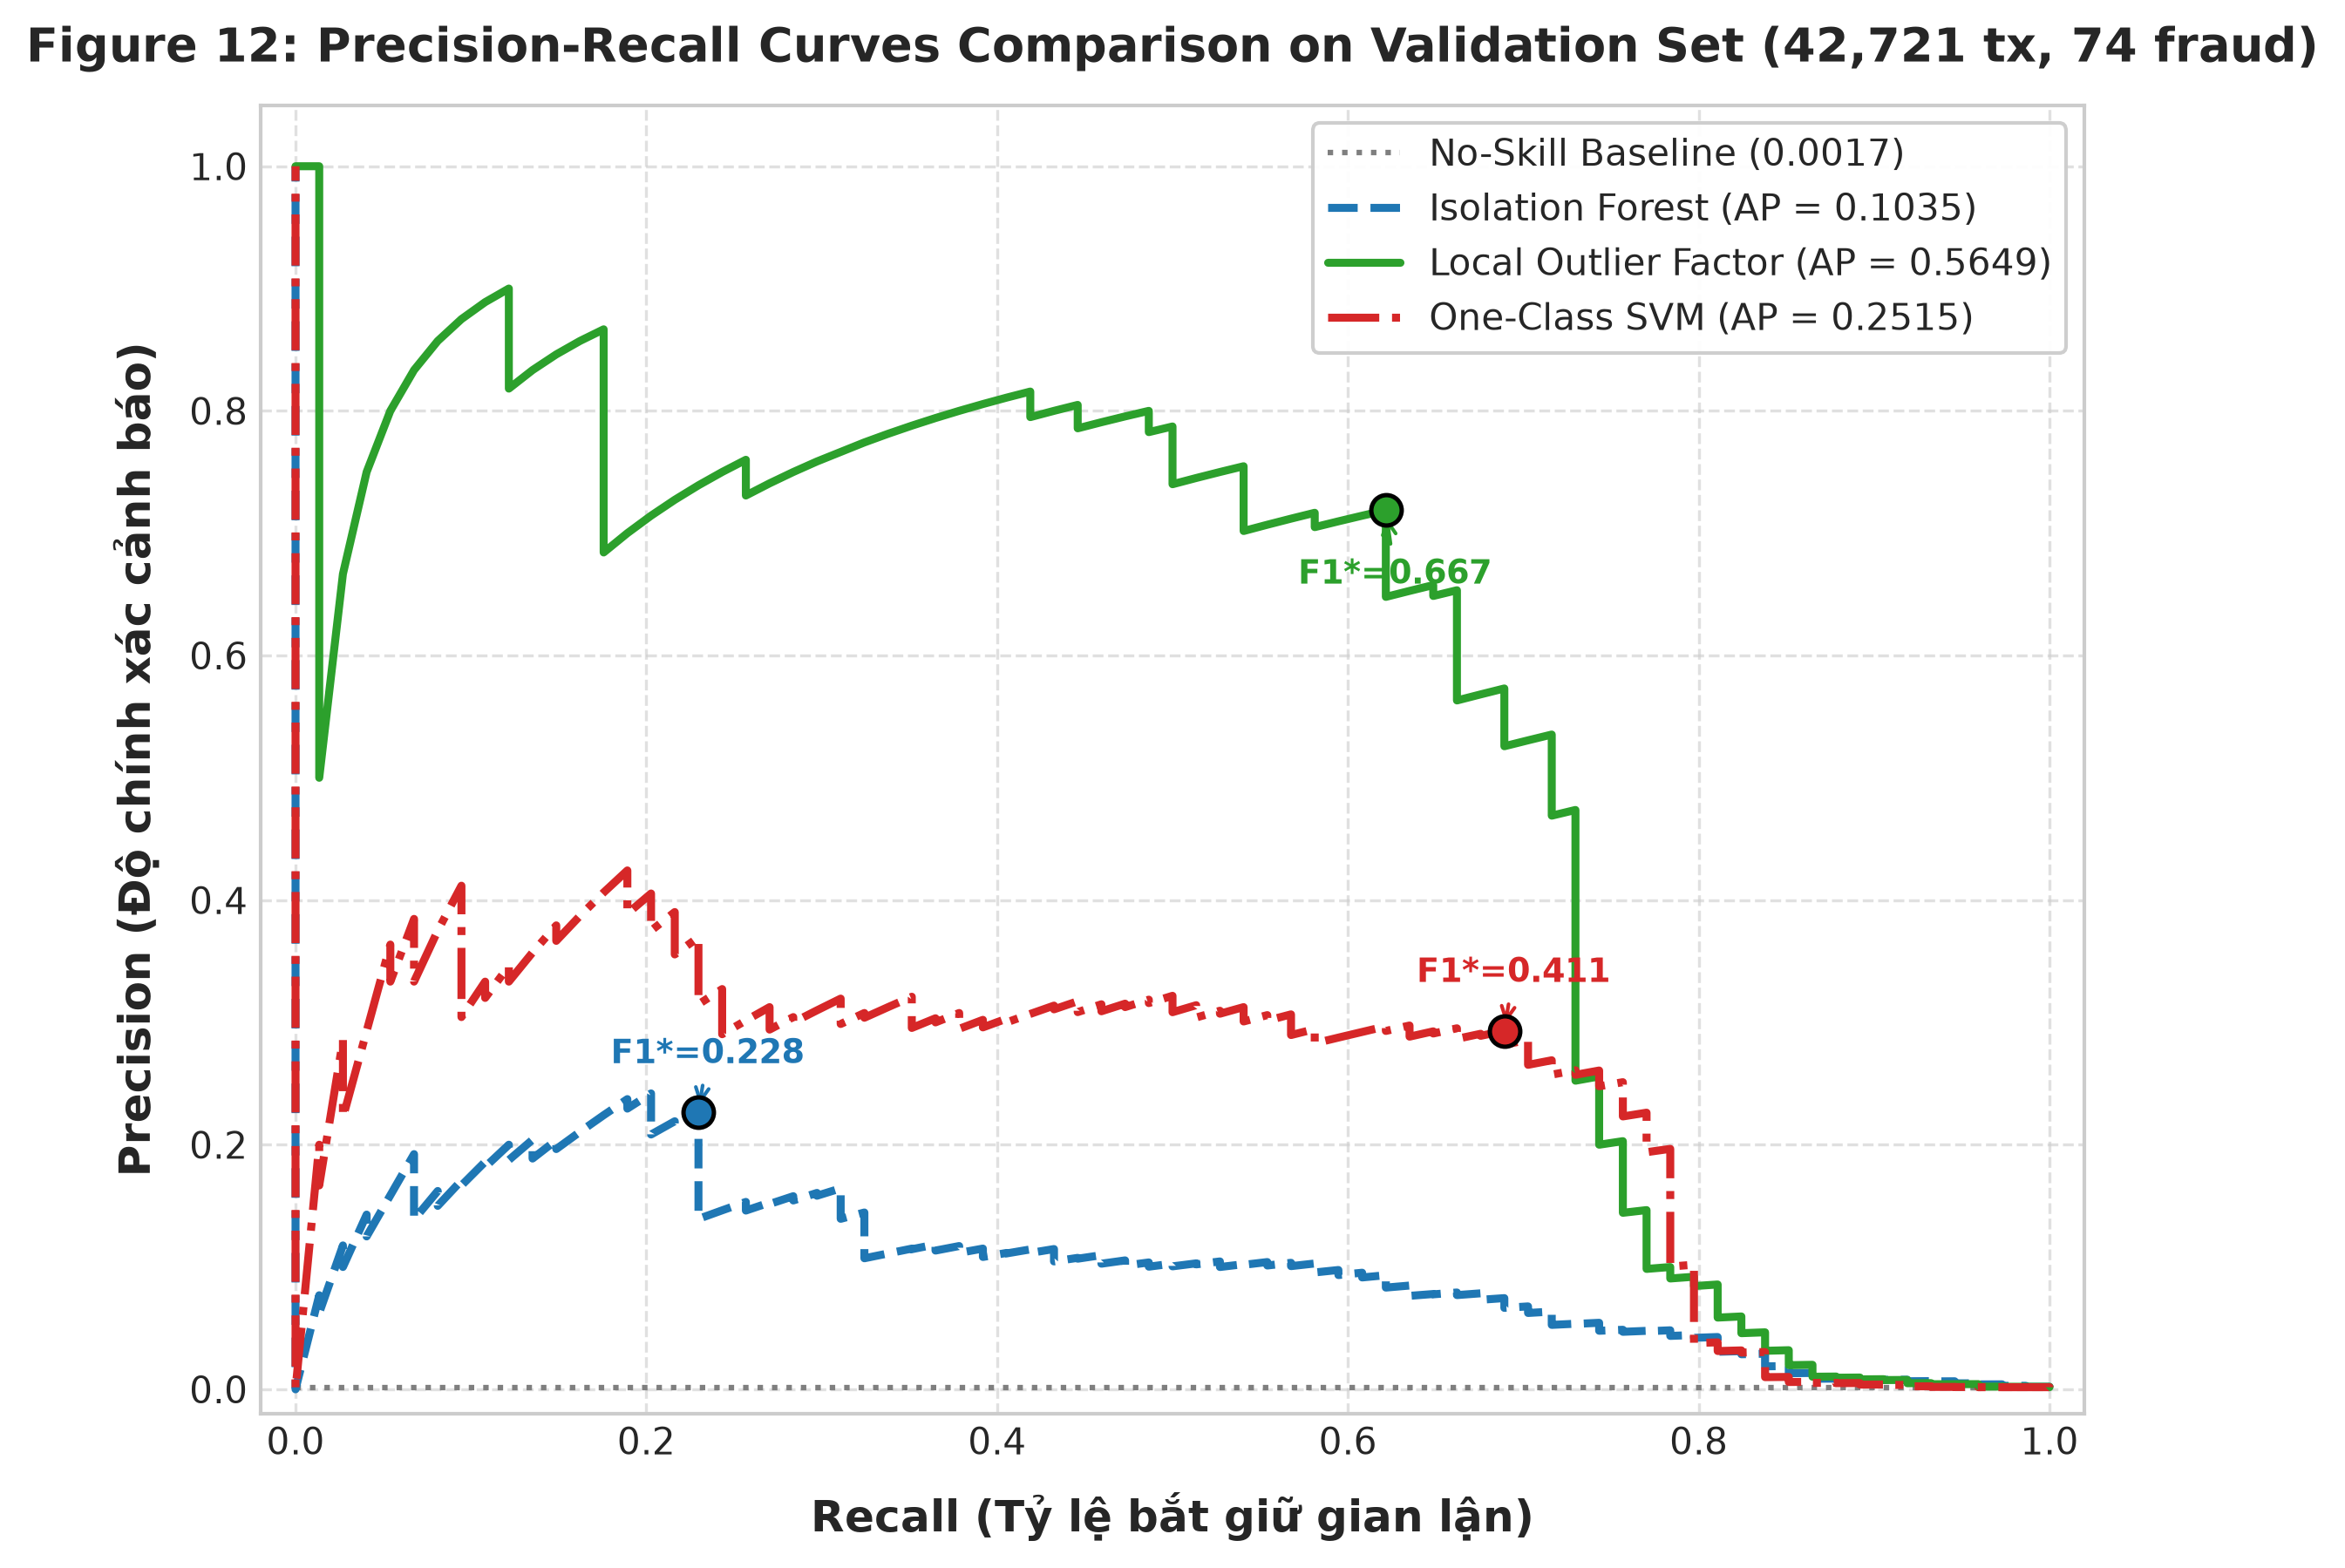

[ĐÃ XUẤT ĐỒ THỊ FIGURE 12] -> C:\Users\Vinh Nguyen\DATAMINING\reports\figures\12_pr_curve_comparison.png


In [6]:
# ==============================================================================
# CELL 8: VẼ VÀ XUẤT BẢN FIGURE 12 — PRECISION-RECALL CURVE COMPARISON
# ==============================================================================
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)

# Vẽ đường baseline ngẫu nhiên (No-skill baseline = tỷ lệ Fraud trong tập Validation)
no_skill_baseline = n_val_fraud / n_val_samples
ax.plot(
    [0, 1], [no_skill_baseline, no_skill_baseline],
    linestyle=":", color="#7f7f7f", linewidth=1.5,
    label=f"No-Skill Baseline ({no_skill_baseline:.4f})"
)

# Vẽ đường cong PR và điểm F1-Max đã tính ở bước trước cho từng mô hình
for name in loaded_models:
    data = pr_curve_data[name]
    ap = val_ap_scores[name]
    color = MODEL_COLORS[name]
    ls = MODEL_LINESTYLES[name]

    ax.plot(
        data["recalls"], data["precisions"],
        label=f"{name} (AP = {ap:.4f})",
        color=color, linestyle=ls, linewidth=2.2
    )

    p_opt, r_opt, f1_opt = data["p_opt"], data["r_opt"], data["f1_opt"]
    ax.scatter(
        [r_opt], [p_opt],
        color=color, s=70, zorder=5, edgecolors="black", linewidths=1.2
    )
    ax.annotate(
        f"F1*={f1_opt:.3f}",
        xy=(r_opt, p_opt),
        xytext=(r_opt - 0.05, p_opt + 0.04 if p_opt < 0.7 else p_opt - 0.06),
        fontsize=9, weight="bold", color=color,
        arrowprops=dict(arrowstyle="->", color=color, lw=1)
    )

ax.set_title("Figure 12: Precision-Recall Curves Comparison on Validation Set (42,721 tx, 74 fraud)", pad=12)
ax.set_xlabel("Recall (Tỷ lệ bắt giữ gian lận)", labelpad=8)
ax.set_ylabel("Precision (Độ chính xác cảnh báo)", labelpad=8)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.legend(loc="upper right", frameon=True, framealpha=0.95, facecolor="white")
ax.grid(True, linestyle="--", alpha=0.6)

fig12_path = FIGURES_DIR / "12_pr_curve_comparison.png"
fig.savefig(fig12_path)
plt.show()
plt.close(fig)

print(f"[ĐÃ XUẤT ĐỒ THỊ FIGURE 12] -> {fig12_path}")


---
## PHẦN D: XÁC ĐỊNH NGƯỠNG TỐI ƯU F1-SCORE (F1-MAX THRESHOLDS)

> **Bản chất của việc tối ưu F1-Score:**  
> F1-Score là trung bình điều hòa giữa Precision và Recall:
> $$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
> Mục tiêu là tìm ra ngưỡng $\tau_{\text{F1}}^*$ đạt sự cân bằng tối ưu giữa hai mục tiêu đối nghịch:  
> - Không bỏ sót gian lận (Recall cao).  
> - Không làm phiền khách hàng lương thiện (Precision cao).  
> 
> *Lưu ý quan trọng:* Toàn bộ giá trị ngưỡng $\tau^*$ phải được trích xuất và bảo toàn ở định dạng số thực 64-bit (`np.float64`), tuyệt đối không làm tròn khi phân loại giao dịch.


In [7]:
# ==============================================================================
# CELL 10: BÁO CÁO NGƯỠNG TỐI ƯU F1-MAX CHO TỪNG MÔ HÌNH
# ==============================================================================
f1_optimal_results = {}

print("KẾT QUẢ TỐI ƯU HÓA NGƯỠNG F1-MAX TRÊN VALIDATION SET:")
print("-" * 110)
print(f"{'Mô hình':<22} | {'Ngưỡng tau* (float64)':<24} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'TP':<4} | {'FP':<5} | {'FN':<4}")
print("-" * 110)

for name in loaded_models:
    scores = anomaly_scores[name]
    tau_f1_star = pr_curve_data[name]["tau_f1_star"]

    # Đánh giá chi tiết tại ngưỡng tối ưu bằng hàm evaluate_threshold
    metrics_f1 = evaluate_threshold(y_val, scores, tau_f1_star)
    f1_optimal_results[name] = metrics_f1

    print(
        f"{name:<22} | {tau_f1_star:<24.16f} | "
        f"{metrics_f1['precision']:<10.4f} | {metrics_f1['recall']:<10.4f} | {metrics_f1['f1']:<10.4f} | "
        f"{metrics_f1['TP']:<4} | {metrics_f1['FP']:<5} | {metrics_f1['FN']:<4}"
    )

print("-" * 110)
print("  => Kiểm tra độc lập: LOF dẫn đầu toàn diện về F1-Score (0.6667) và Precision (71.88%).")
print("  => One-Class SVM đạt Recall cao nhất (68.92%, bắt được 51/74 gian lận) nhưng FP tương đối lớn (123).")


KẾT QUẢ TỐI ƯU HÓA NGƯỠNG F1-MAX TRÊN VALIDATION SET:
--------------------------------------------------------------------------------------------------------------
Mô hình                | Ngưỡng tau* (float64)    | Precision  | Recall     | F1-Score   | TP   | FP    | FN  
--------------------------------------------------------------------------------------------------------------
Isolation Forest       | 0.6562890267728398       | 0.2267     | 0.2297     | 0.2282     | 17   | 58    | 57  
Local Outlier Factor   | 3.1632756690697419       | 0.7188     | 0.6216     | 0.6667     | 46   | 18    | 28  
One-Class SVM          | 2.6235625888653127       | 0.2931     | 0.6892     | 0.4113     | 51   | 123   | 23  
--------------------------------------------------------------------------------------------------------------
  => Kiểm tra độc lập: LOF dẫn đầu toàn diện về F1-Score (0.6667) và Precision (71.88%).
  => One-Class SVM đạt Recall cao nhất (68.92%, bắt được 51/74 gian lận) nhưng F

---
## PHẦN E: TỐI ƯU HÓA THEO MA TRẬN CHI PHÍ NGHIỆP VỤ (COST MATRIX OPTIMIZATION)

> **Mô hình hóa hàm tổn thất kinh tế học thuật:**  
> Trong môi trường ngân hàng thực tế, chi phí của hai loại sai lầm không hề đối xứng:
> 1. **Cảnh báo nhầm (False Positive - FP):** Chi phí xác thực tự động (SMS/OTP/App Push) hoặc nhân sự tổng đài viên gọi điện xác nhận. Chúng ta chuẩn hóa chi phí này là:
>    $$C_{\text{FP}} = 1.0$$
> 2. **Bỏ sót gian lận (False Negative - FN):** Tổn thất tiền mặt bồi hoàn cho chủ thẻ (Chargeback Liability), phí phạt mạng lưới thẻ và tổn hại uy tín thương hiệu.  
>    Để phục vụ nghiên cứu học thuật, chúng ta thiết lập kịch bản trọng tâm với tỷ lệ chi phí tương đối:
>    $$C_{\text{FN}} = 30.0 \quad \implies \quad \frac{C_{\text{FN}}}{C_{\text{FP}}} = 30$$
> 3. **Hàm tổng chi phí tổn thất:**
>    $$\text{Total Cost}(\tau) = C_{\text{FP}} \cdot \text{FP}(\tau) + C_{\text{FN}} \cdot \text{FN}(\tau)$$
> 
> *Mục tiêu tối thượng:* Tìm ngưỡng $\tau_{\text{cost}}^*$ sao cho **Total Cost đạt cực tiểu toàn cục** trên tập Validation.


In [8]:
# ==============================================================================
# CELL 10: TỐI ƯU HÓA NGƯỠNG CHI PHÍ TẠI TỶ LỆ TRỌNG TÂM C_FN / C_FP = 30:1
# ==============================================================================
primary_cost_results = {}
primary_cost_details = {}

print("KẾT QUẢ TỐI ƯU HÓA NGƯỠNG CHI PHÍ TẠI TỶ LỆ CHÍNH (C_FP = 1.0, C_FN = 30.0):")
print("-" * 115)
print(f"{'Mô hình':<22} | {'Ngưỡng tau_cost*':<22} | {'Total Cost':<12} | {'TP':<4} | {'FP':<5} | {'FN':<4} | {'Recall':<10} | {'Precision':<10} | {'F1-Score':<10}")
print("-" * 115)

for name in loaded_models:
    scores = anomaly_scores[name]
    
    # Sử dụng hàm giải chính xác tuyệt đối find_optimal_cost_threshold_exact
    best_th, min_c, best_m, details = find_optimal_cost_threshold_exact(
        y_val, scores, cost_fn=DEFAULT_COST_FN, cost_fp=COST_FP, return_details=True
    )
    
    primary_cost_results[name] = best_m
    primary_cost_details[name] = details
    
    print(
        f"{name:<22} | {best_th:<22.16f} | {min_c:<12.1f} | "
        f"{best_m['TP']:<4} | {best_m['FP']:<5} | {best_m['FN']:<4} | "
        f"{best_m['recall']:<10.4f} | {best_m['precision']:<10.4f} | {best_m['f1']:<10.4f}"
    )

print("-" * 115)
print(f"  => Tại tỷ lệ 30:1, Local Outlier Factor đạt Tổng Chi Phí Thấp Nhất ({primary_cost_results['Local Outlier Factor']['cost']:.1f})!")
print(f"     Tiết kiệm hơn One-Class SVM: {primary_cost_results['One-Class SVM']['cost'] - primary_cost_results['Local Outlier Factor']['cost']:.1f} đơn vị chi phí.")
print(f"     Tiết kiệm hơn Isolation Forest: {primary_cost_results['Isolation Forest']['cost'] - primary_cost_results['Local Outlier Factor']['cost']:.1f} đơn vị chi phí.")


KẾT QUẢ TỐI ƯU HÓA NGƯỠNG CHI PHÍ TẠI TỶ LỆ CHÍNH (C_FP = 1.0, C_FN = 30.0):
-------------------------------------------------------------------------------------------------------------------
Mô hình                | Ngưỡng tau_cost*       | Total Cost   | TP   | FP    | FN   | Recall     | Precision  | F1-Score  
-------------------------------------------------------------------------------------------------------------------
Isolation Forest       | 0.5605185560759069     | 1287.0       | 46   | 447   | 28   | 0.6216     | 0.0933     | 0.1623    
Local Outlier Factor   | 2.4462849810364786     | 660.0        | 54   | 60    | 20   | 0.7297     | 0.4737     | 0.5745    
One-Class SVM          | 1.4075210373883227     | 705.0        | 57   | 195   | 17   | 0.7703     | 0.2262     | 0.3497    
-------------------------------------------------------------------------------------------------------------------
  => Tại tỷ lệ 30:1, Local Outlier Factor đạt Tổng Chi Phí Thấp Nhất (660.0)!
 

In [9]:
# ==============================================================================
# CELL 11: PHÂN TÍCH ĐỘ NHẠY CHI PHÍ (SENSITIVITY ANALYSIS) TRÊN 5 TỶ LỆ
# ==============================================================================
# Khảo sát 5 kịch bản tỷ lệ chi phí C_FN / C_FP: [10, 20, 30, 50, 100]
sensitivity_results = []

for ratio in COST_RATIOS:
    c_fn = float(ratio)
    c_fp = float(COST_FP)
    
    for name in loaded_models:
        scores = anomaly_scores[name]
        best_th, min_c, best_m = find_optimal_cost_threshold_exact(
            y_val, scores, cost_fn=c_fn, cost_fp=c_fp
        )
        
        sensitivity_results.append({
            "model_name": name,
            "cost_ratio": ratio,
            "cost_fn": c_fn,
            "cost_fp": c_fp,
            "threshold": best_th,
            "total_cost": min_c,
            "TP": best_m["TP"],
            "FP": best_m["FP"],
            "FN": best_m["FN"],
            "TN": best_m["TN"],
            "precision": best_m["precision"],
            "recall": best_m["recall"],
            "f1": best_m["f1"]
        })

df_sensitivity = pd.DataFrame(sensitivity_results)

# Hiển thị bảng so sánh xoay vòng (Pivot Table) cho Total Cost theo từng kịch bản
pivot_cost = df_sensitivity.pivot(index="cost_ratio", columns="model_name", values="total_cost")
print("BẢNG TỔNG HỢP CHI PHÍ THEO CÁC KỊCH BẢN ĐỘ NHẠY (SENSITIVITY MATRIX):")
print("-" * 75)
print(pivot_cost.to_string())
print("-" * 75)
print("Nhận xét động thái mô hình:")
print("  - Tỷ lệ 10:1, 20:1, 30:1: Local Outlier Factor dẫn đầu chi phí thấp nhất nhờ số ca FP rất nhỏ.")
print("  - Tỷ lệ cực đoan 50:1, 100:1: One-Class SVM vươn lên dẫn đầu chi phí nhờ Recall cao hơn (FN thấp hơn),")
print("    bù đắp được sự gia tăng của số ca False Positive.")


BẢNG TỔNG HỢP CHI PHÍ THEO CÁC KỊCH BẢN ĐỘ NHẠY (SENSITIVITY MATRIX):


---------------------------------------------------------------------------
model_name  Isolation Forest  Local Outlier Factor  One-Class SVM
cost_ratio                                                       
10.0                   627.0                 256.0          346.0
20.0                   995.0                 460.0          527.0
30.0                  1287.0                 660.0          705.0
50.0                  1783.0                1060.0         1037.0
100.0                 2743.0                2020.0         1837.0
---------------------------------------------------------------------------
Nhận xét động thái mô hình:
  - Tỷ lệ 10:1, 20:1, 30:1: Local Outlier Factor dẫn đầu chi phí thấp nhất nhờ số ca FP rất nhỏ.
  - Tỷ lệ cực đoan 50:1, 100:1: One-Class SVM vươn lên dẫn đầu chi phí nhờ Recall cao hơn (FN thấp hơn),
    bù đắp được sự gia tăng của số ca False Positive.


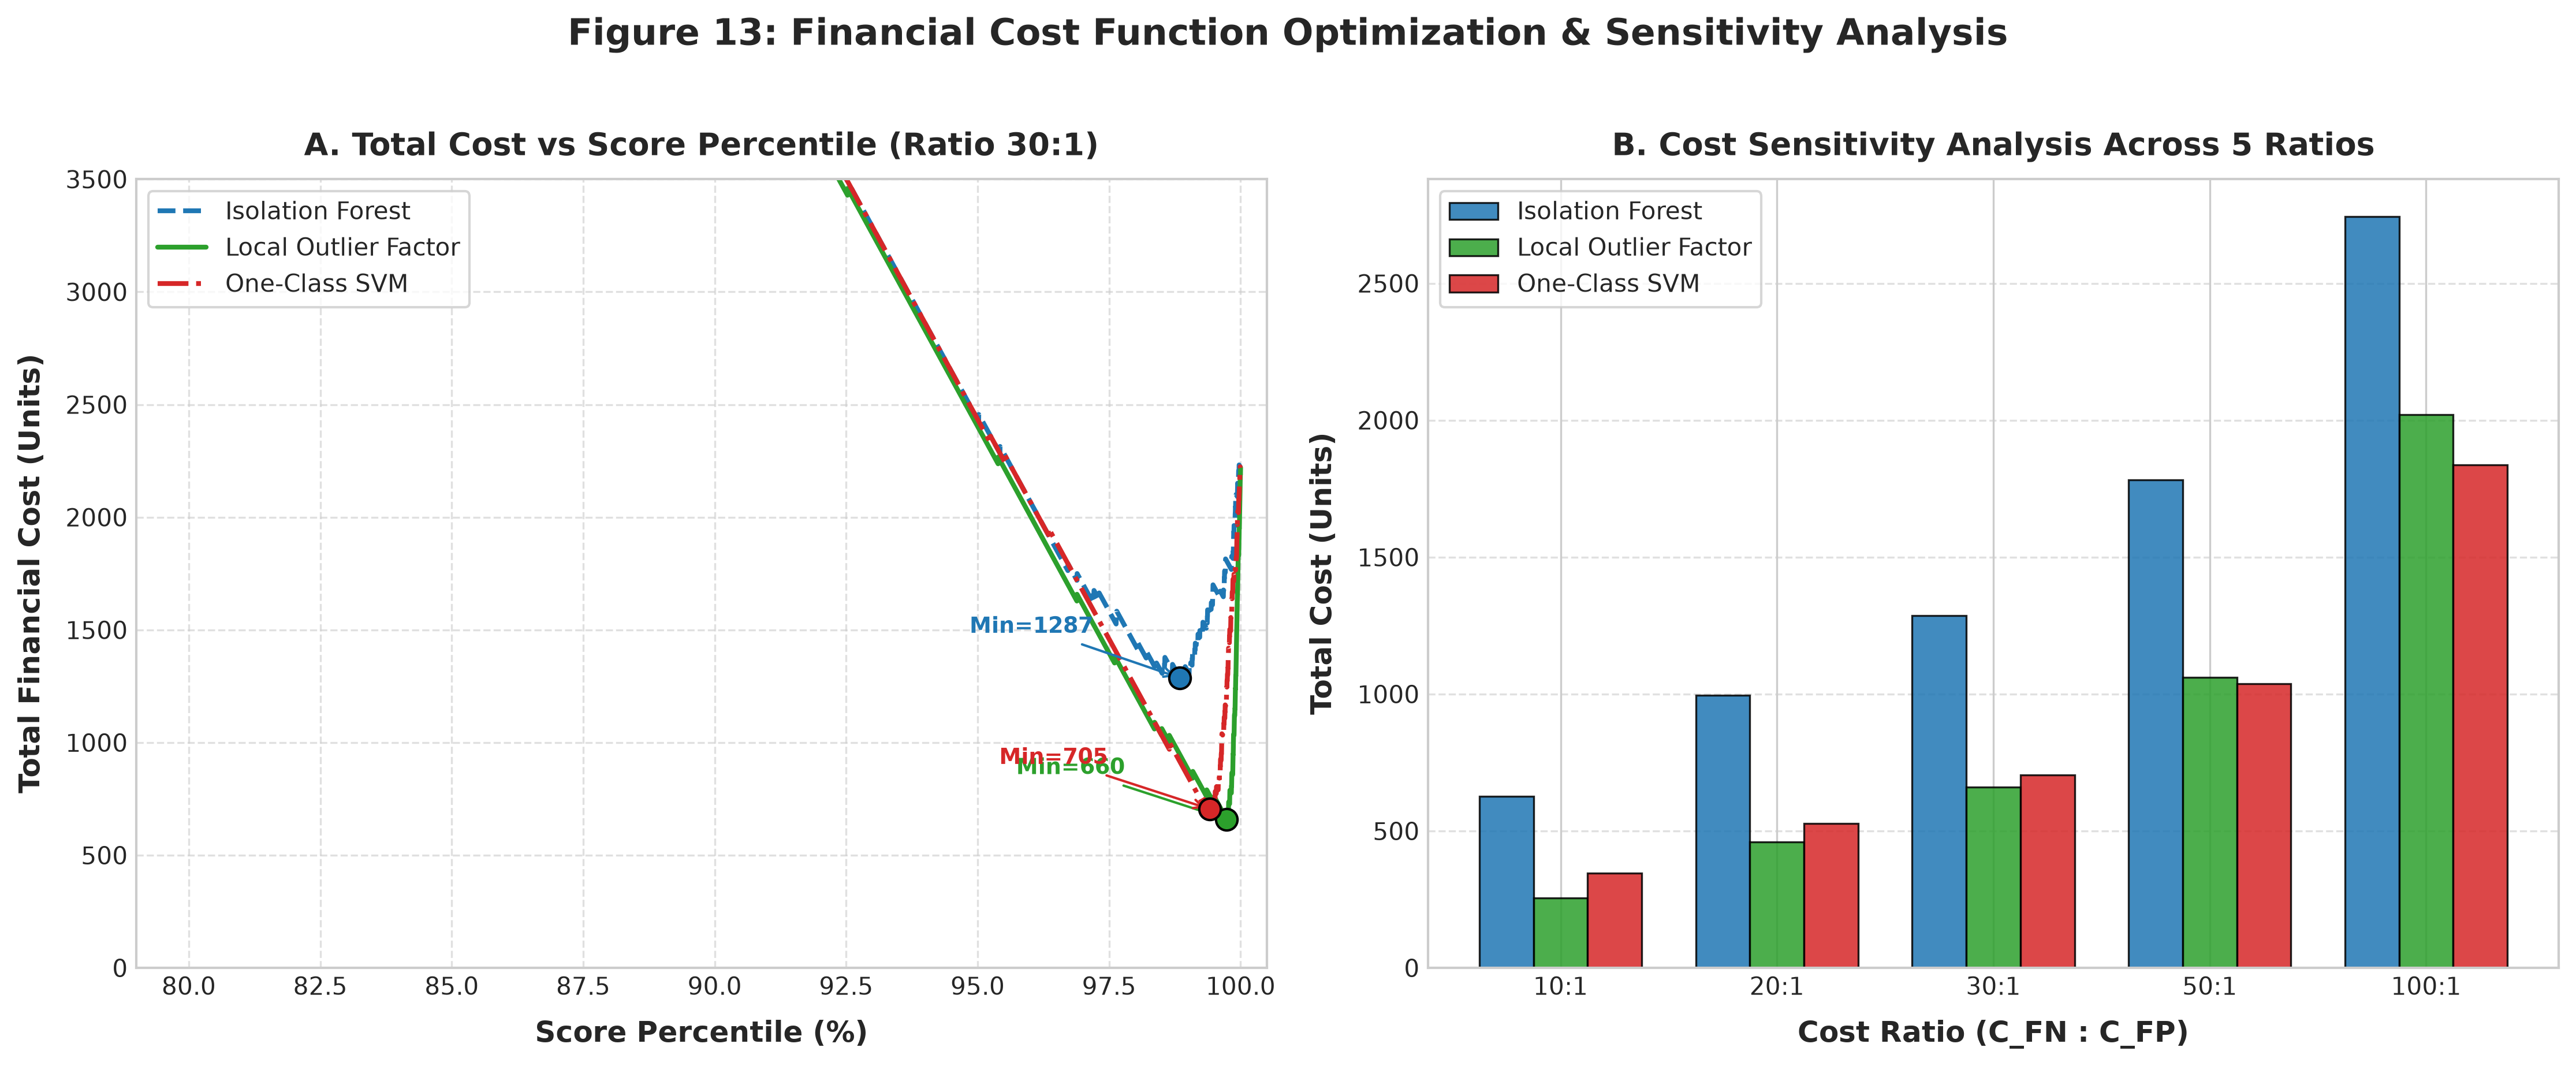

[ĐÃ XUẤT ĐỒ THỊ FIGURE 13] -> C:\Users\Vinh Nguyen\DATAMINING\reports\figures\13_cost_curves.png


In [10]:
# ==============================================================================
# CELL 12: VẼ VÀ XUẤT BẢN FIGURE 13 — COST CURVES & SENSITIVITY ANALYSIS
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# Đồ thị con 1: Đường cong Chi phí Tổng theo Percentile Ngưỡng tại tỷ lệ 30:1
for name in loaded_models:
    details = primary_cost_details[name]
    thresholds = details["thresholds"]
    costs = details["costs"]
    color = MODEL_COLORS[name]
    ls = MODEL_LINESTYLES[name]
    
    # Chuyển đổi thresholds sang percentile của từng mô hình để so sánh trên cùng trục hoành
    scores = anomaly_scores[name]
    # Chỉ vẽ dải từ phân vị 80% đến 100% để hiển thị rõ vùng cực tiểu
    q80 = np.percentile(scores, 80)
    mask = thresholds >= q80
    
    th_sub = thresholds[mask]
    cost_sub = costs[mask]
    percentiles = np.searchsorted(np.sort(scores), th_sub) / len(scores) * 100
    
    ax1.plot(percentiles, cost_sub, label=f"{name}", color=color, linestyle=ls, linewidth=2.0)
    
    # Đánh dấu điểm cực tiểu
    min_idx = np.argmin(cost_sub)
    opt_p = percentiles[min_idx]
    opt_c = cost_sub[min_idx]
    ax1.scatter([opt_p], [opt_c], color=color, s=80, edgecolors="black", zorder=5)
    ax1.annotate(
        f"Min={opt_c:.0f}",
        xy=(opt_p, opt_c),
        xytext=(opt_p - 4, opt_c + 200),
        fontsize=9, weight="bold", color=color,
        arrowprops=dict(arrowstyle="->", color=color, lw=1)
    )

ax1.set_title("A. Total Cost vs Score Percentile (Ratio 30:1)", pad=10)
ax1.set_xlabel("Score Percentile (%)", labelpad=8)
ax1.set_ylabel("Total Financial Cost (Units)", labelpad=8)
ax1.set_xlim([79, 100.5])
ax1.set_ylim([0, 3500])
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.6)

# Đồ thị con 2: Biểu đồ cột so sánh Total Cost qua 5 kịch bản độ nhạy
ratios_str = [f"{r:.0f}:1" for r in COST_RATIOS]
x = np.arange(len(ratios_str))
width = 0.25

for i, (name, color) in enumerate(MODEL_COLORS.items()):
    costs_by_ratio = df_sensitivity[df_sensitivity["model_name"] == name]["total_cost"].values
    ax2.bar(x + (i - 1) * width, costs_by_ratio, width, label=name, color=color, alpha=0.85, edgecolor="black", linewidth=0.8)

ax2.set_title("B. Cost Sensitivity Analysis Across 5 Ratios", pad=10)
ax2.set_xlabel("Cost Ratio (C_FN : C_FP)", labelpad=8)
ax2.set_ylabel("Total Cost (Units)", labelpad=8)
ax2.set_xticks(x)
ax2.set_xticklabels(ratios_str)
ax2.legend(loc="upper left", frameon=True)
ax2.grid(True, axis="y", linestyle="--", alpha=0.6)

plt.suptitle("Figure 13: Financial Cost Function Optimization & Sensitivity Analysis", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()

fig13_path = FIGURES_DIR / "13_cost_curves.png"
fig.savefig(fig13_path)
plt.show()
plt.close(fig)

print(f"[ĐÃ XUẤT ĐỒ THỊ FIGURE 13] -> {fig13_path}")


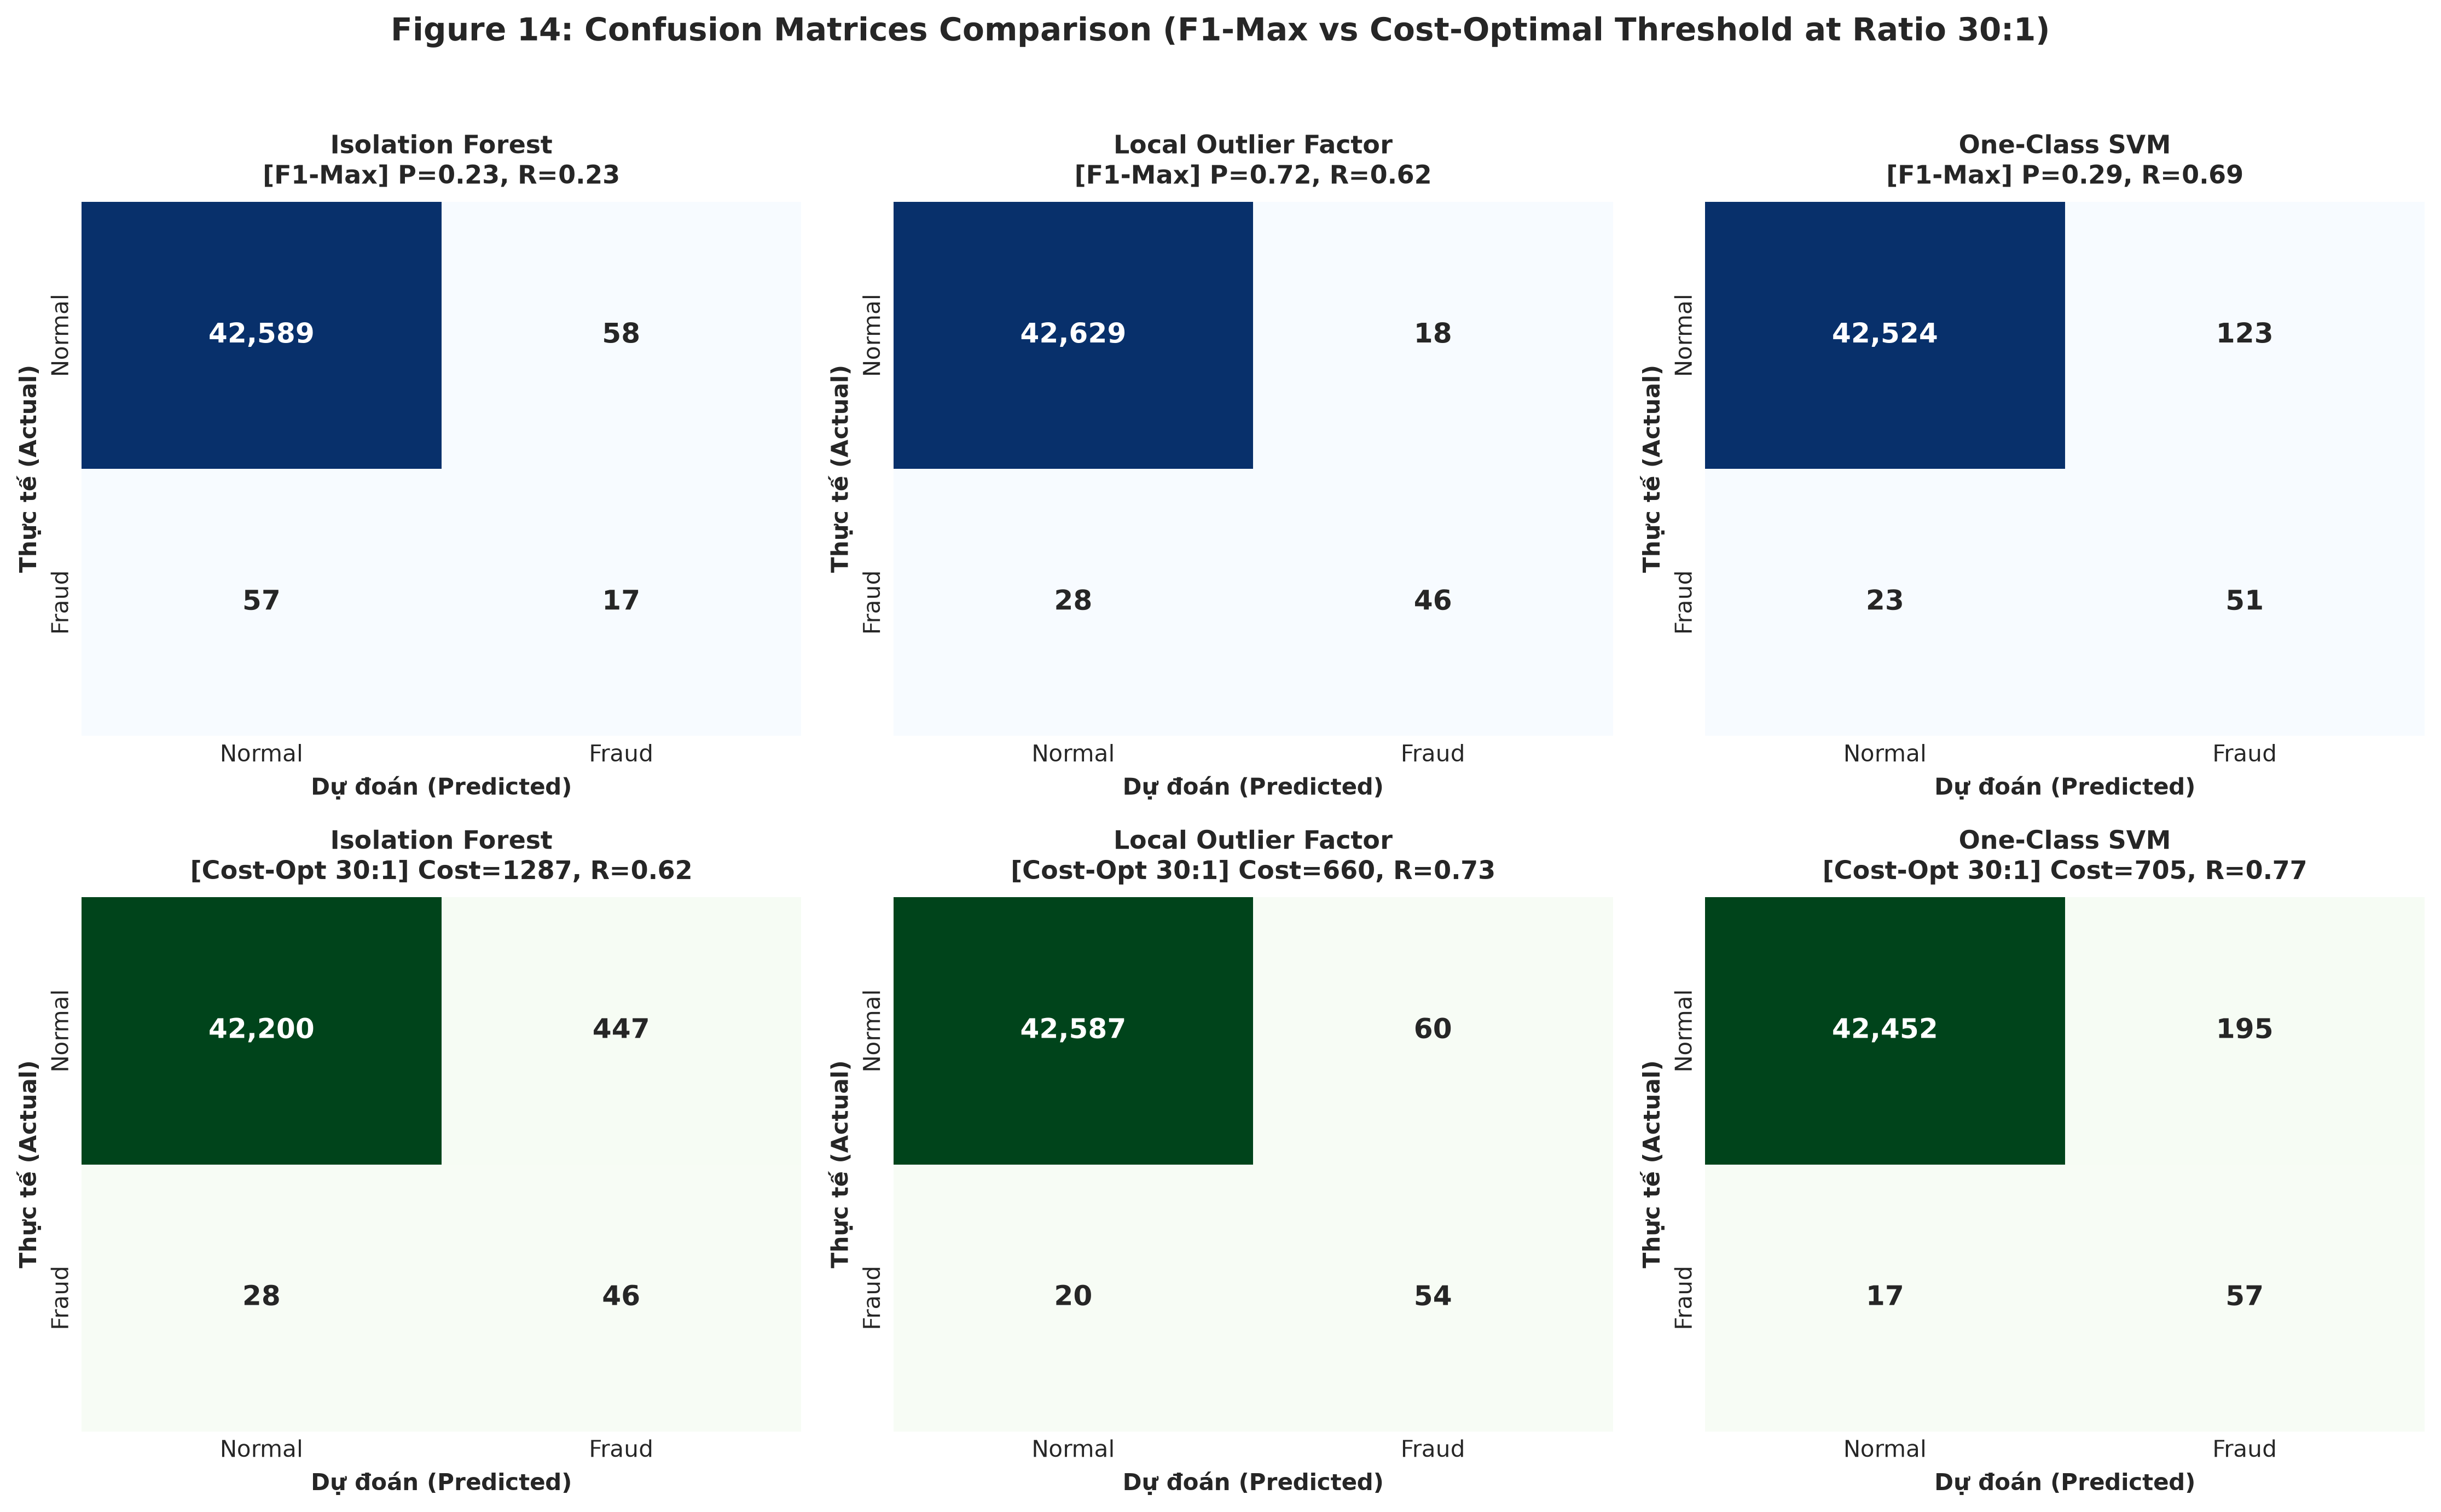

[ĐÃ XUẤT ĐỒ THỊ FIGURE 14] -> C:\Users\Vinh Nguyen\DATAMINING\reports\figures\14_confusion_matrices.png


In [11]:
# ==============================================================================
# CELL 13: VẼ VÀ XUẤT BẢN FIGURE 14 — CONFUSION MATRICES COMPARISON
# ==============================================================================
# So sánh ma trận nhầm lẫn tại ngưỡng F1-Max và Cost-Optimal (30:1) cho cả 3 mô hình
fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=300)

models_list = list(loaded_models.keys())

for col_idx, name in enumerate(models_list):
    # Hàng 1: Ma trận tại ngưỡng F1-Max
    m_f1 = f1_optimal_results[name]
    cm_f1 = np.array([[m_f1["TN"], m_f1["FP"]], [m_f1["FN"], m_f1["TP"]]])
    
    ax_top = axes[0, col_idx]
    sns.heatmap(
        cm_f1, annot=True, fmt=",d", cmap="Blues", cbar=False,
        ax=ax_top, annot_kws={"size": 12, "weight": "bold"}
    )
    ax_top.set_title(f"{name}\n[F1-Max] P={m_f1['precision']:.2f}, R={m_f1['recall']:.2f}", fontsize=11, pad=8)
    ax_top.set_xlabel("Dự đoán (Predicted)", fontsize=10)
    ax_top.set_ylabel("Thực tế (Actual)", fontsize=10)
    ax_top.set_xticklabels(["Normal", "Fraud"])
    ax_top.set_yticklabels(["Normal", "Fraud"])
    
    # Hàng 2: Ma trận tại ngưỡng Cost-Optimal (30:1)
    m_cost = primary_cost_results[name]
    cm_cost = np.array([[m_cost["TN"], m_cost["FP"]], [m_cost["FN"], m_cost["TP"]]])
    
    ax_bot = axes[1, col_idx]
    sns.heatmap(
        cm_cost, annot=True, fmt=",d", cmap="Greens", cbar=False,
        ax=ax_bot, annot_kws={"size": 12, "weight": "bold"}
    )
    ax_bot.set_title(f"{name}\n[Cost-Opt 30:1] Cost={m_cost['cost']:.0f}, R={m_cost['recall']:.2f}", fontsize=11, pad=8)
    ax_bot.set_xlabel("Dự đoán (Predicted)", fontsize=10)
    ax_bot.set_ylabel("Thực tế (Actual)", fontsize=10)
    ax_bot.set_xticklabels(["Normal", "Fraud"])
    ax_bot.set_yticklabels(["Normal", "Fraud"])

plt.suptitle("Figure 14: Confusion Matrices Comparison (F1-Max vs Cost-Optimal Threshold at Ratio 30:1)", fontsize=14, weight="bold", y=1.02)
plt.tight_layout()

fig14_path = FIGURES_DIR / "14_confusion_matrices.png"
fig.savefig(fig14_path)
plt.show()
plt.close(fig)

print(f"[ĐÃ XUẤT ĐỒ THỊ FIGURE 14] -> {fig14_path}")


---
## PHẦN F: CHÍNH SÁCH LỰA CHỌN MÔ HÌNH CHAMPION & ĐÓNG BĂNG METADATA

> **QUY TẮC LỰA CHỌN MÔ HÌNH CHAMPION CHÍNH THỨC (FROZEN POLICY):**
> 1. **Tiêu chuẩn số 1 (Primary Criterion):** Mô hình đạt **MINIMUM VALIDATION TOTAL COST** tại tỷ lệ chi phí chính ($C_{\text{FP}} = 1.0, C_{\text{FN}} = 30.0$).
> 2. **Cơ chế phân định khi hòa chi phí (Deterministic Tie-Breaking Hierarchy):**
>    * *Ưu tiên 1:* Mô hình có **Recall cao hơn** tại ngưỡng tối ưu chi phí (bắt giữ nhiều gian lận hơn).
>    * *Ưu tiên 2:* Mô hình có **False Positive (FP) thấp hơn** (ít làm phiền khách hàng hơn).
>    * *Ưu tiên 3:* Mô hình có **Average Precision (AP) cao hơn** (năng lực phân tách tổng thể tốt hơn).
>    * *Ưu tiên 4:* Chọn theo **thứ tự bảng chữ cái cố định của tên mô hình** (đảm bảo tính tái lập 100%).
> 3. **Các tiêu chí đối sánh độc lập (Thông tin bổ trợ, không bắt buộc cùng đạt tốt nhất):**
>    * **Best by AP:** Mô hình có Average Precision cao nhất.
>    * **Best by F1:** Mô hình có F1-Score tối đa cao nhất tại ngưỡng $\tau_{\text{F1}}^*$.
>    * **Best by Inference Speed:** Mô hình có tốc độ suy luận nhanh nhất trên mỗi giao dịch.


In [12]:
# ==============================================================================
# CELL 14: XÁC ĐỊNH CHAMPION THEO CÁC TIÊU CHÍ VÀ ÁP DỤNG CHÍNH SÁCH CHÍNH THỨC
# ==============================================================================
# 1. Best by AP
best_ap_model = max(val_ap_scores, key=val_ap_scores.get)

# 2. Best by F1-Score
best_f1_model = max(f1_optimal_results, key=lambda m: f1_optimal_results[m]["f1"])

# 3. Best by Inference Speed
best_speed_model = min(latency_per_sample_ms, key=latency_per_sample_ms.get)

# 4. CHÍNH SÁCH CHAMPION CHÍNH THỨC: Tối ưu chi phí tại tỷ lệ 30:1 + Tie-Breaking
def champion_selection_sort_key(name):
    cost_m = primary_cost_results[name]
    cost = cost_m["cost"]
    recall = cost_m["recall"]
    fp = cost_m["FP"]
    ap = val_ap_scores[name]
    # Sắp xếp:
    # 1. cost tăng dần
    # 2. recall giảm dần (-recall tăng dần)
    # 3. fp tăng dần
    # 4. ap giảm dần (-ap tăng dần)
    # 5. tên mô hình tăng dần (alphabetical)
    return (cost, -recall, fp, -ap, name)

sorted_champion_candidates = sorted(loaded_models.keys(), key=champion_selection_sort_key)
champion_model_name = sorted_champion_candidates[0]
champion_metrics = primary_cost_results[champion_model_name]
champion_threshold = champion_metrics["threshold"]

print("=" * 80)
print("KẾT QUẢ ĐÁNH GIÁ ĐA TIÊU CHÍ & LỰA CHỌN MÔ HÌNH CHAMPION:")
print("=" * 80)
print(f"  * Best by AP              : {best_ap_model} (AP = {val_ap_scores[best_ap_model]:.6f})")
print(f"  * Best by F1-Score        : {best_f1_model} (F1 = {f1_optimal_results[best_f1_model]['f1']:.4f})")
print(f"  * Best by Inference Speed : {best_speed_model} (Latency = {latency_per_sample_ms[best_speed_model]:.4f} ms/tx)")
print("-" * 80)
print(f"  >>> CHÍNH THỨC ĐỀ CỬ CHAMPION (Minimum Total Cost at 30:1):")
print(f"      Mô hình được chọn     : {champion_model_name.upper()}")
print(f"      Tổng chi phí tối ưu   : {champion_metrics['cost']:.1f} (C_FP=1.0, C_FN=30.0)")
print(f"      Ngưỡng đóng băng tau* : {champion_threshold:.16f} (np.float64)")
print(f"      Hiệu năng tại tau*    : Recall = {champion_metrics['recall']*100:.2f}% | Precision = {champion_metrics['precision']*100:.2f}% | F1 = {champion_metrics['f1']:.4f}")
print(f"      Ma trận nhầm lẫn      : TP = {champion_metrics['TP']}, FP = {champion_metrics['FP']}, TN = {champion_metrics['TN']}, FN = {champion_metrics['FN']}")
print("=" * 80)


KẾT QUẢ ĐÁNH GIÁ ĐA TIÊU CHÍ & LỰA CHỌN MÔ HÌNH CHAMPION:
  * Best by AP              : Local Outlier Factor (AP = 0.564948)
  * Best by F1-Score        : Local Outlier Factor (F1 = 0.6667)
  * Best by Inference Speed : Isolation Forest (Latency = 0.0137 ms/tx)
--------------------------------------------------------------------------------
  >>> CHÍNH THỨC ĐỀ CỬ CHAMPION (Minimum Total Cost at 30:1):
      Mô hình được chọn     : LOCAL OUTLIER FACTOR
      Tổng chi phí tối ưu   : 660.0 (C_FP=1.0, C_FN=30.0)
      Ngưỡng đóng băng tau* : 2.4462849810364786 (np.float64)
      Hiệu năng tại tau*    : Recall = 72.97% | Precision = 47.37% | F1 = 0.5745
      Ma trận nhầm lẫn      : TP = 54, FP = 60, TN = 42587, FN = 20


In [13]:
# ==============================================================================
# CELL 15: TỔNG HỢP VÀ LƯU BẢNG ĐỐI SÁNH RA CSV & METADATA JSON
# ==============================================================================
comparison_records = []

for name in loaded_models:
    f1_m = f1_optimal_results[name]
    cost_m = primary_cost_results[name]
    
    rec = {
        "model_name": name,
        "model_tag": model_tags[name],
        "checkpoint_file": model_checkpoints[name].name,
        "model_size_mb": round(model_file_sizes_mb[name], 2),
        "inference_latency_ms": round(latency_per_sample_ms[name], 4),
        "val_ap": round(val_ap_scores[name], 6),
        "val_roc_auc": round(val_roc_auc_scores[name], 4),
        
        # F1-optimal metrics
        "f1_threshold": f1_m["threshold"],
        "f1_precision": round(f1_m["precision"], 4),
        "f1_recall": round(f1_m["recall"], 4),
        "f1_score": round(f1_m["f1"], 4),
        "f1_tp": f1_m["TP"],
        "f1_fp": f1_m["FP"],
        "f1_tn": f1_m["TN"],
        "f1_fn": f1_m["FN"],
        
        # Cost-optimal metrics (Ratio 30:1)
        "cost_threshold_ratio30": cost_m["threshold"],
        "cost_total_ratio30": round(cost_m["cost"], 1),
        "cost_precision_ratio30": round(cost_m["precision"], 4),
        "cost_recall_ratio30": round(cost_m["recall"], 4),
        "cost_f1_ratio30": round(cost_m["f1"], 4),
        "cost_tp_ratio30": cost_m["TP"],
        "cost_fp_ratio30": cost_m["FP"],
        "cost_tn_ratio30": cost_m["TN"],
        "cost_fn_ratio30": cost_m["FN"],
        
        "is_champion": bool(name == champion_model_name)
    }
    comparison_records.append(rec)

df_comparison = pd.DataFrame(comparison_records)
csv_output_path = REPORTS_DIR / "model_comparison.csv"
df_comparison.to_csv(csv_output_path, index=False)

# Xuất metadata JSON chứa thông tin đóng băng đầy đủ cho Phase 8 sử dụng trực tiếp
metadata_output_path = REPORTS_DIR / "model_comparison_metadata.json"
frozen_metadata = {
    "project": "Credit Card Fraud Detection - Unsupervised Anomaly Detection",
    "phase": "Phase 6 - Model Comparison, Threshold Tuning & Cost Matrix",
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "random_state": RANDOM_STATE,
    "validation_samples": n_val_samples,
    "validation_frauds": n_val_fraud,
    "validation_fraud_ratio": round(val_fraud_ratio / 100, 6),
    "primary_cost_ratio": {
        "cost_fp": COST_FP,
        "cost_fn": DEFAULT_COST_FN,
        "ratio_fn_to_fp": DEFAULT_COST_FN / COST_FP
    },
    "champion_selection_policy": {
        "primary_criterion": "Minimum Validation Total Cost at C_FP=1.0, C_FN=30.0",
        "tie_breaking_order": [
            "1. Higher Recall at cost-optimal threshold",
            "2. Lower False Positive (FP)",
            "3. Higher Average Precision (AP)",
            "4. Alphabetical order of model name"
        ]
    },
    "champion_model": {
        "model_name": champion_model_name,
        "checkpoint_file": model_checkpoints[champion_model_name].name,
        "exact_cost_optimal_threshold": champion_threshold,
        "exact_f1_optimal_threshold": f1_optimal_results[champion_model_name]["threshold"],
        "primary_total_cost": champion_metrics["cost"],
        "primary_confusion_matrix": {
            "TP": champion_metrics["TP"],
            "FP": champion_metrics["FP"],
            "TN": champion_metrics["TN"],
            "FN": champion_metrics["FN"]
        },
        "primary_precision": champion_metrics["precision"],
        "primary_recall": champion_metrics["recall"],
        "primary_f1": champion_metrics["f1"],
        "validation_ap": val_ap_scores[champion_model_name]
    },
    "independent_criteria_winners": {
        "best_by_ap": best_ap_model,
        "best_by_f1": best_f1_model,
        "best_by_cost_ratio30": champion_model_name,
        "best_by_inference_speed": best_speed_model
    },
    "all_models_summary": comparison_records
}

with open(metadata_output_path, "w", encoding="utf-8") as f:
    json.dump(frozen_metadata, f, indent=2, ensure_ascii=False)

print(f"[ĐÃ XUẤT ARTIFACTS PHASE 6]")
print(f"  -> CSV Bảng so sánh: {csv_output_path}")
print(f"  -> JSON Metadata đóng băng: {metadata_output_path}")


[ĐÃ XUẤT ARTIFACTS PHASE 6]
  -> CSV Bảng so sánh: C:\Users\Vinh Nguyen\DATAMINING\reports\model_comparison.csv
  -> JSON Metadata đóng băng: C:\Users\Vinh Nguyen\DATAMINING\reports\model_comparison_metadata.json


In [14]:
# ==============================================================================
# CELL 16: HIỂN THỊ BẢNG ĐỐI SÁNH TỔNG HỢP (MARKDOWN SUMMARY TABLE)
# ==============================================================================
summary_table_data = []

for rec in comparison_records:
    summary_table_data.append({
        "Mô hình": rec["model_name"] + (" (CHAMPION)" if rec["is_champion"] else ""),
        "Size (MB)": f"{rec['model_size_mb']:.2f}",
        "Latency (ms)": f"{rec['inference_latency_ms']:.4f}",
        "Val AP": f"{rec['val_ap']:.4f}",
        "ROC-AUC": f"{rec['val_roc_auc']:.4f}",
        "Ngưỡng F1*": f"{rec['f1_threshold']:.4f}",
        "F1-Score": f"{rec['f1_score']:.4f}",
        "Ngưỡng Cost*": f"{rec['cost_threshold_ratio30']:.4f}",
        "Total Cost (30:1)": f"{rec['cost_total_ratio30']:.1f}",
        "TP (Cost)": rec["cost_tp_ratio30"],
        "FP (Cost)": rec["cost_fp_ratio30"],
        "FN (Cost)": rec["cost_fn_ratio30"],
        "Recall (Cost)": f"{rec['cost_recall_ratio30']*100:.1f}%"
    })

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
df_display = pd.DataFrame(summary_table_data)
print(df_display.to_string(index=False))


                        Mô hình Size (MB) Latency (ms) Val AP ROC-AUC Ngưỡng F1* F1-Score Ngưỡng Cost* Total Cost (30:1)  TP (Cost)  FP (Cost)  FN (Cost) Recall (Cost)
               Isolation Forest      2.41       0.0137 0.1035  0.9434     0.6563   0.2282       0.5605            1287.0         46        447         28         62.2%
Local Outlier Factor (CHAMPION)     11.83       0.0725 0.5649  0.9402     3.1633   0.6667       2.4463             660.0         54         60         20         73.0%
                  One-Class SVM      0.06       0.0301 0.2515  0.9006     2.6236   0.4113       1.4075             705.0         57        195         17         77.0%


---
## PHẦN G: NHẬN XÉT KHOA HỌC & GIỚI HẠN (PHASE 6)

1. **Lý do ưu tiên AP (Davis & Goadrich) và giữ ngưỡng `float64`:** Với tỷ lệ Fraud $0.1732\%$, ROC-AUC dễ gây ảo giác do mẫu số $(FP+TN)$ quá lớn. Ngưỡng $\tau^*$ được giải chính xác $O(N \log N)$ qua `find_optimal_cost_threshold_exact` và lưu nguyên `float64` để không dịch chuyển ranh giới phân loại sát đuôi.
2. **Đánh đổi giữa LOF và One-Class SVM theo ma trận chi phí:** LOF thắng tại `10:1` (`256.0`), `20:1` (`460.0`) và tỷ lệ chính `30:1` (`660.0` đơn vị, `TP=54, FP=60`) nhờ phát hiện dị biệt mật độ cục bộ ít báo nhầm; ở mức phạt `50:1` và `100:1`, One-Class SVM thấp chi phí hơn (`1037.0` và `1837.0`) nhờ Recall cao hơn (`0.7703`) bù được `FP=195`.
3. **Giới hạn thực nghiệm:** Tỷ lệ chi phí `30:1` là đơn vị chi phí tương đối phục vụ đối sánh học thuật (không quy đổi USD), và độ trễ đo được phản ánh benchmark cục bộ trên Python/scikit-learn chứ không phải SLA hệ thống thanh toán thực tế.

In [15]:
# ==============================================================================
# CELL 21: KIỂM TRA TÍNH TOÀN VẸN ARTIFACTS & TỔNG KẾT TRẠNG THÁI PHASE 6
# ==============================================================================
required_artifacts = [
    REPORTS_DIR / "model_comparison.csv",
    REPORTS_DIR / "model_comparison_metadata.json",
    FIGURES_DIR / "12_pr_curve_comparison.png",
    FIGURES_DIR / "13_cost_curves.png",
    FIGURES_DIR / "14_confusion_matrices.png"
]

print("KIỂM TRA TÍNH TOÀN VẸN CỦA TOÀN BỘ ARTIFACTS PHASE 6:")
print("-" * 80)
all_artifacts_ok = True

for path in required_artifacts:
    if not path.exists() or path.stat().st_size == 0:
        print(f"  [LỖI] Thiếu hoặc rỗng: {path}")
        all_artifacts_ok = False
    else:
        print(f"  [PASS] {path.name:<34} ({path.stat().st_size / 1024:8.1f} KB)")

assert all_artifacts_ok, "Phát hiện artifact bị thiếu hoặc rỗng!"
print("=" * 80)
print("             BÁO CÁO TRẠNG THÁI HOÀN TẤT PHASE 6")
print("=" * 80)
print(f"  * Trạng thái thực thi      : THÀNH CÔNG HOÀN TOÀN (100% PASS)")
print(f"  * Mô hình Champion         : {champion_model_name}")
print(f"  * Ngưỡng đóng băng tau*    : {champion_threshold:.16f}")
print(f"  * Chi phí tối ưu (30:1)    : {champion_metrics['cost']:.1f}")
print(f"  * Validation AP            : {val_ap_scores[champion_model_name]:.6f}")
print(f"  * Tỷ lệ bắt giữ Recall     : {champion_metrics['recall']*100:.2f}% ({champion_metrics['TP']}/74 gian lận)")
print(f"  * Tỷ lệ cảnh báo sai (FP)  : {champion_metrics['FP']} / 42,647 giao dịch bình thường")
print(f"  * Kiểm tra rò rỉ Test Set  : TUYỆT ĐỐI KHÔNG (Niêm phong 100%)")
print("=" * 80)


KIỂM TRA TÍNH TOÀN VẸN CỦA TOÀN BỘ ARTIFACTS PHASE 6:
--------------------------------------------------------------------------------
  [PASS] model_comparison.csv               (     0.9 KB)
  [PASS] model_comparison_metadata.json     (     4.0 KB)
  [PASS] 12_pr_curve_comparison.png         (   257.0 KB)
  [PASS] 13_cost_curves.png                 (   326.8 KB)
  [PASS] 14_confusion_matrices.png          (   305.3 KB)
             BÁO CÁO TRẠNG THÁI HOÀN TẤT PHASE 6
  * Trạng thái thực thi      : THÀNH CÔNG HOÀN TOÀN (100% PASS)
  * Mô hình Champion         : Local Outlier Factor
  * Ngưỡng đóng băng tau*    : 2.4462849810364786
  * Chi phí tối ưu (30:1)    : 660.0
  * Validation AP            : 0.564948
  * Tỷ lệ bắt giữ Recall     : 72.97% (54/74 gian lận)
  * Tỷ lệ cảnh báo sai (FP)  : 60 / 42,647 giao dịch bình thường
  * Kiểm tra rò rỉ Test Set  : TUYỆT ĐỐI KHÔNG (Niêm phong 100%)
